## Data Preparation - **Time Series ECG**

In [1]:
import os
import seaborn as sns
import zipfile
import wfdb
import pandas as pd
import random
import matplotlib.pyplot as plt
import numpy as np

In [2]:
output_dir = "../datasets/valid_time-series-csv/"

csv_files = [f for f in os.listdir(output_dir) if f.endswith(".csv")]

In [7]:
# Seleziona 3 file casuali per vedere se ci sono differenze nella lunghezza
random_files = random.sample(csv_files, min(3, len(csv_files)))  # Garantisce di non superare il numero di file disponibili
random_file_list = []
df_list = []
# salva solo 3 ecg per analisi future su un campione
for file_name in random_files:
    file_path = os.path.join(output_dir, file_name)
    random_file_list.append(file_path)
    df_list.append(pd.read_csv(file_path))
    print(f"File consired : {file_name}")

File consired : 10016810_49564151.csv
File consired : 10130585_44756917.csv
File consired : 10190684_47845425.csv


In [4]:
# Crea liste df e file contenente ecg di tutti i pazienti
df_all_list = []
all_file_list = []
for file_name in csv_files:
    file_path = os.path.join(output_dir, file_name)
    all_file_list.append(file_name)
    df_all_list.append(pd.read_csv(file_path))
len(df_all_list)

1100

### **Data Cleaning**

In [5]:
for i, df in enumerate(df_all_list):
    if not df.shape[0] == 5000:
        print(i, df.shape)
print("OK")

OK


In [6]:
count = 0
null_TS_list = []

for i in range(len(df_all_list)):
    if df_all_list[i].isnull().values.any():
        print("Ci sono NaN nel DataFrame? SI", all_file_list[i])
        count += 1
        null_TS_list.append(all_file_list[i])

indices_to_remove = [all_file_list.index(file) for file in null_TS_list]

all_file_list = [file for idx, file in enumerate(all_file_list) if idx not in indices_to_remove]
df_all_list = [df for idx, df in enumerate(df_all_list) if idx not in indices_to_remove]

print("COUNT: ", count)
print("File rimossi:", null_TS_list)
print("Rimangono in all_file_list:", len(all_file_list))
print("Rimangono in df_all_list:", len(df_all_list))


Ci sono NaN nel DataFrame? SI 10029484_40093576.csv
Ci sono NaN nel DataFrame? SI 10039709_48212074.csv
Ci sono NaN nel DataFrame? SI 10049778_49049006.csv
Ci sono NaN nel DataFrame? SI 10052077_42863915.csv
Ci sono NaN nel DataFrame? SI 10087135_40964170.csv
Ci sono NaN nel DataFrame? SI 10087981_42424904.csv
Ci sono NaN nel DataFrame? SI 10095570_47899547.csv
Ci sono NaN nel DataFrame? SI 10127480_40775100.csv
Ci sono NaN nel DataFrame? SI 10168519_49285963.csv
Ci sono NaN nel DataFrame? SI 10172206_44852838.csv
Ci sono NaN nel DataFrame? SI 10215754_47633390.csv
Ci sono NaN nel DataFrame? SI 10225882_46765733.csv
COUNT:  12
File rimossi: ['10029484_40093576.csv', '10039709_48212074.csv', '10049778_49049006.csv', '10052077_42863915.csv', '10087135_40964170.csv', '10087981_42424904.csv', '10095570_47899547.csv', '10127480_40775100.csv', '10168519_49285963.csv', '10172206_44852838.csv', '10215754_47633390.csv', '10225882_46765733.csv']
Rimangono in all_file_list: 1088
Rimangono in df_a

### **Offset Translation**

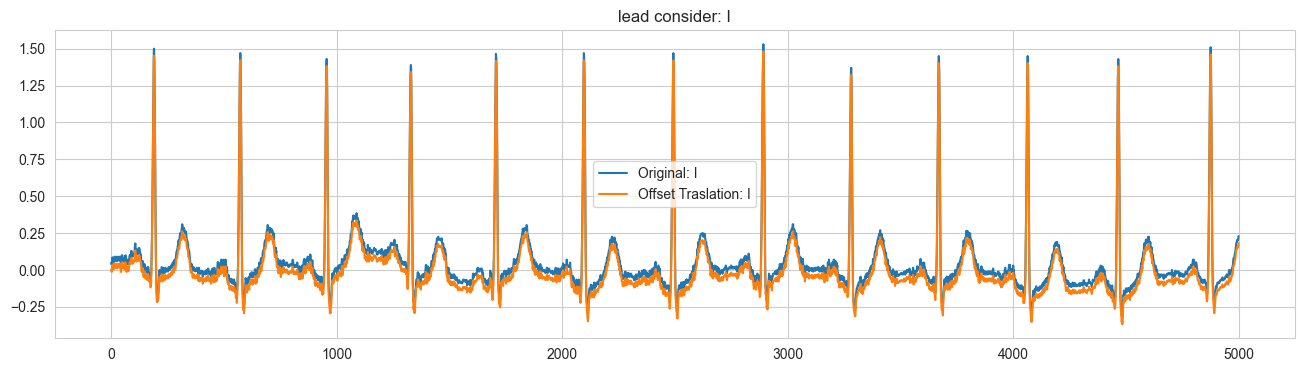

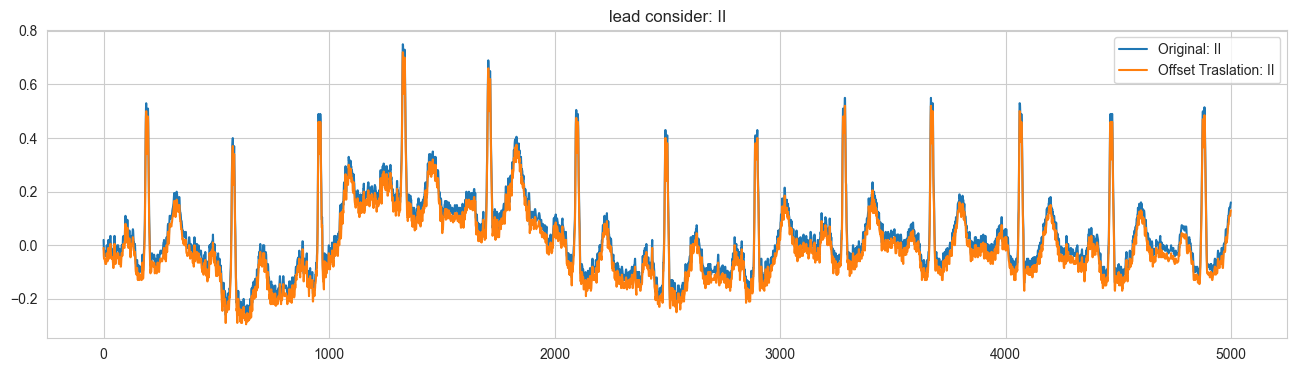

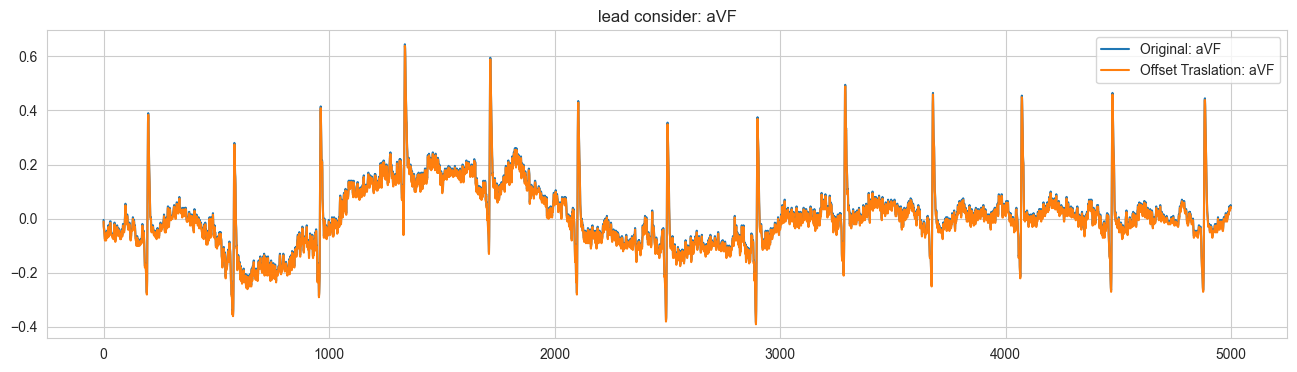

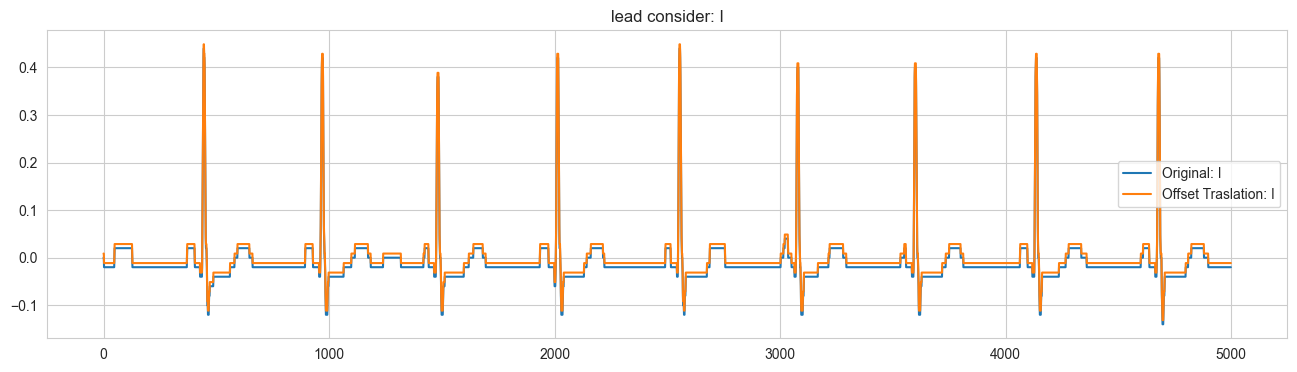

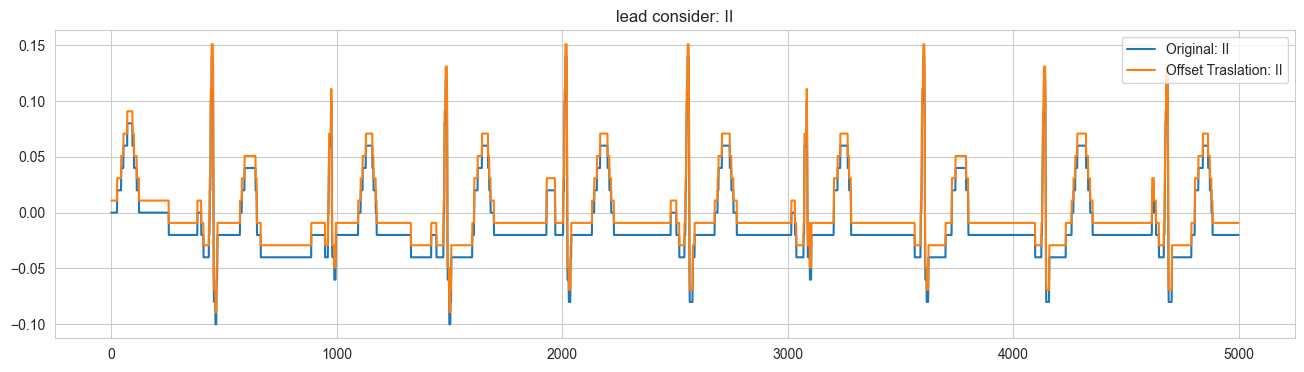

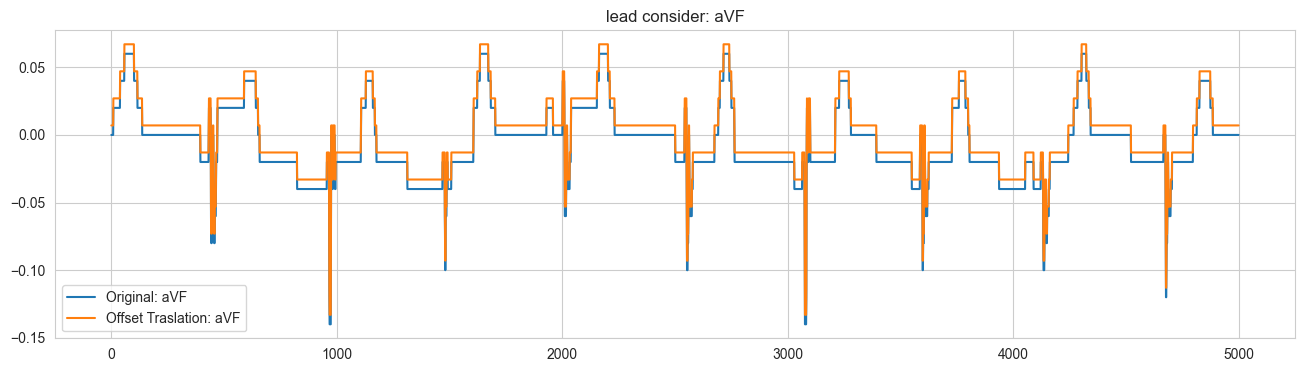

In [14]:
# offset translation
for df in [df_list[0], df_list[2]]:
    for column in ['I', 'II', 'aVF']:
        plt.figure(figsize=(16, 4))
        plt.title(f"lead consider: {column}")
        # plt.plot(df[col], label=f"Original: {column}", alpha=0.6)
        # plt.plot(df[col] - df[col].mean(), label=f"Offset Translated: {column}", linestyle='--')
        plt.plot(df[column], label=f"Original: {column}")
        plt.plot(df[column] - df[column].mean(), label=f"Offset Traslation: {column}")
        plt.legend()
        plt.show()

In [16]:
# Lista per salvare i DataFrame aggiornati con l'offset translation applicato
df_offset_translated_list = []

# Itera comportamento per ciascun ECG di ogni paziente
for df in df_all_list:
    # Crea una copia del DataFrame per l'offset translation
    df_offset_translated = df.copy()

    for column in df.columns:  # Applica l'offset translation a ciascun segnale
        df_offset_translated[column] = (df[column] - df[column].mean())#.interpolate(method='polynomial', order=3)
        # df_offset_translated[column] = df_offset_translated[column].bfill()
        # df_offset_translated[column] = df_offset_translated[column].ffill()

    df_offset_translated_list.append(df_offset_translated)

In [17]:
# Controllo valori mancanti post rimozione prima distorsione
for i, df in enumerate(df_offset_translated_list):
    for column in df.columns:
        nan_in_column = df[column].isnull().sum()
        if nan_in_column > 0:
            print(f"{i} Numero di NaN nella colonna '{column}': {nan_in_column}")
            print(df[column].isnull())

### **Amplitude scaling** (Normalizzare l'ampiezza)

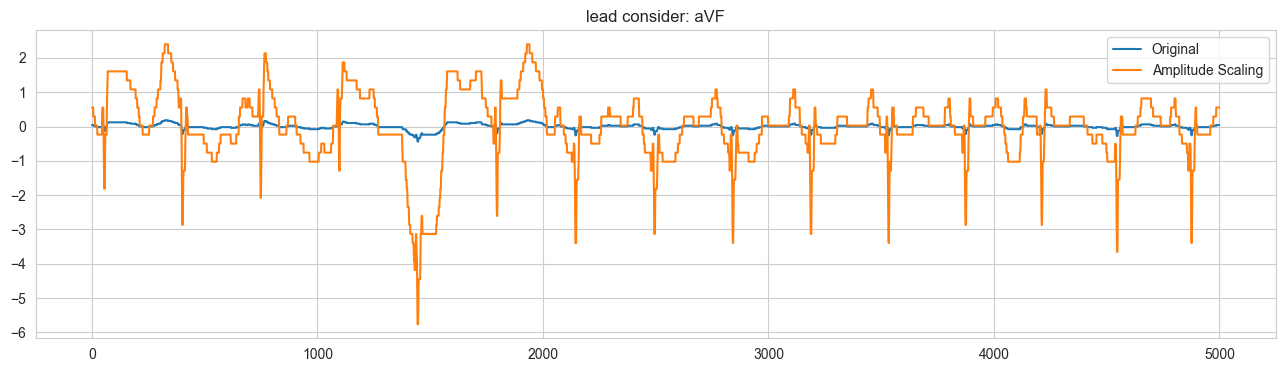

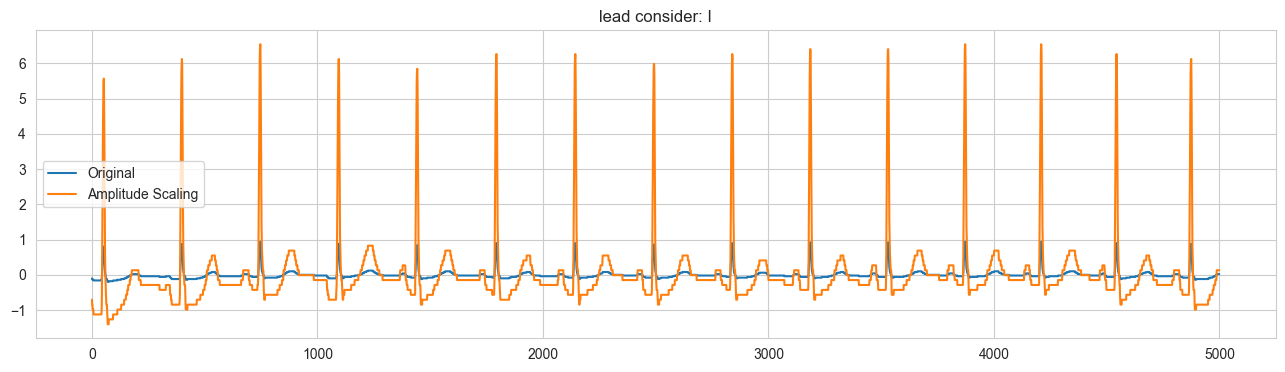

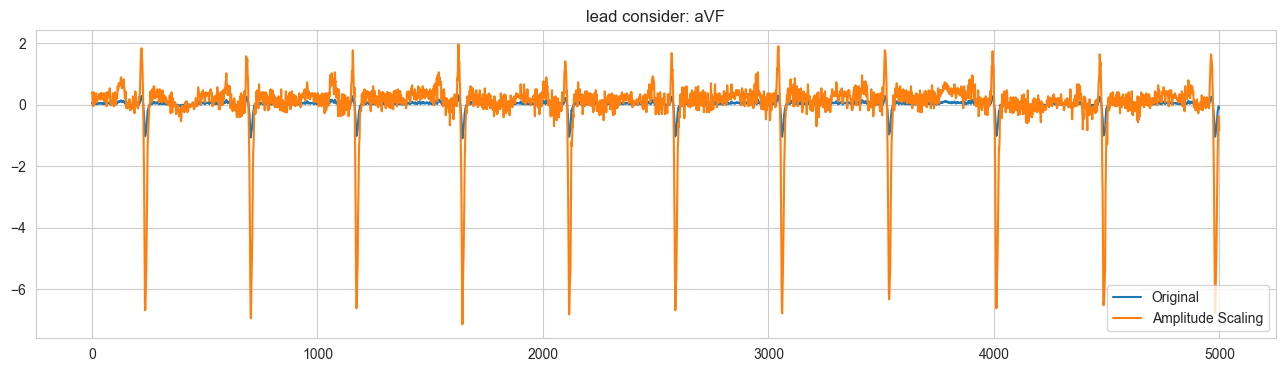

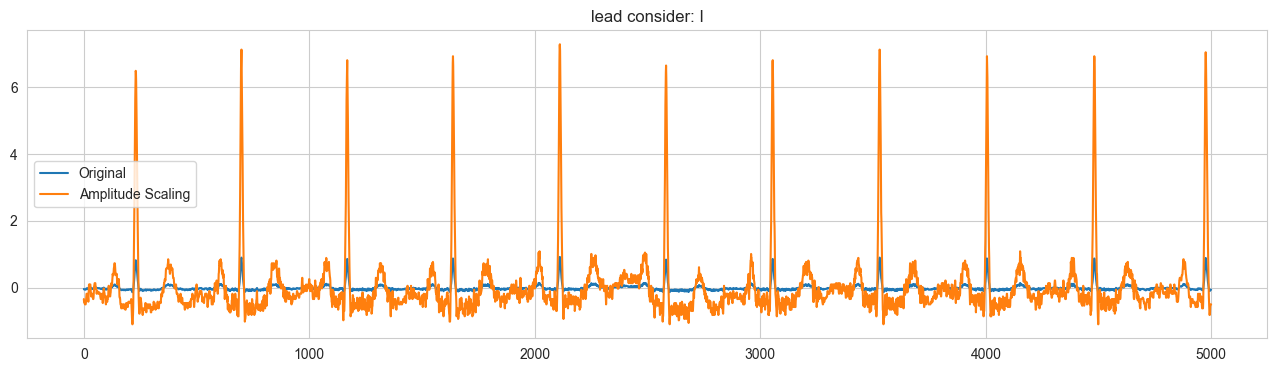

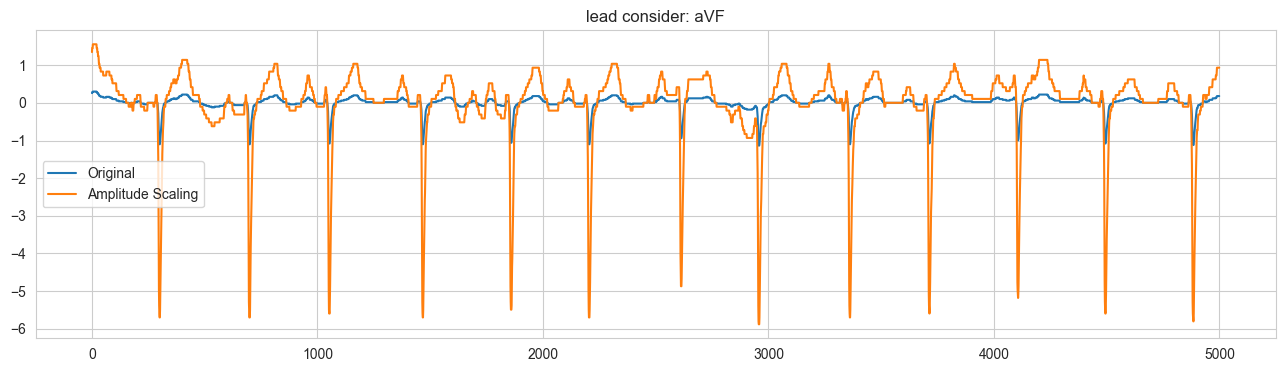

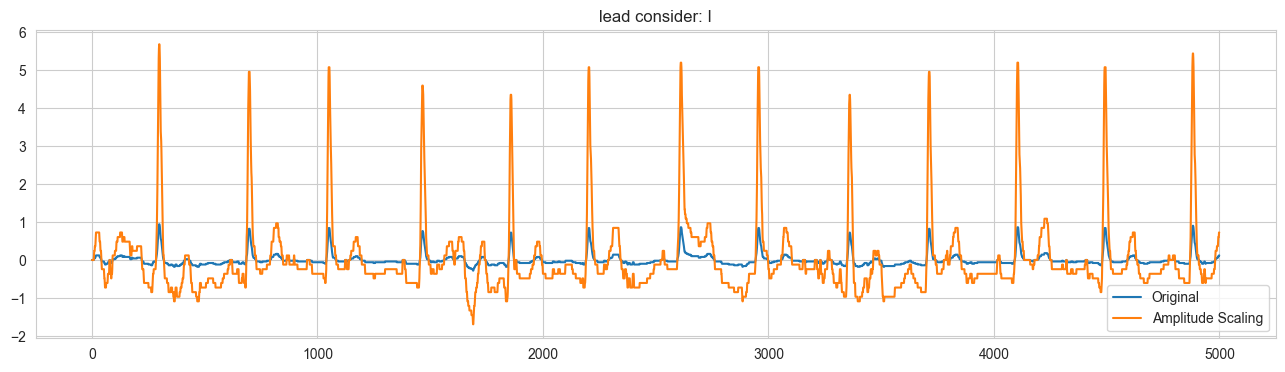

In [19]:
## Farlo specifico 

# plt.plot((ts1 - ts1.mean())/ts1.std())
# offset translation
for df in [df_offset_translated_list[20], df_offset_translated_list[10], df_offset_translated_list[100]]:
    for column in ['aVF', 'I']:
        plt.figure(figsize=(16, 4))
        plt.title(f"lead consider: {column}")
        # plt.plot(df[col], label=f"Original: {column}", alpha=0.6)
        # plt.plot(df[col] - df[col].mean(), label=f"Offset Translated: {column}", linestyle='--')
        plt.plot(df[column], label="Original")
        plt.plot((df[column] - df[column].mean())/df[column].std(), label="Amplitude Scaling")
        plt.legend()
        plt.show()


In [20]:
# Amplitude Scaling fatto su dataset traslato
# Lista per salvare i DataFrame aggiornati con l'offset translation applicato
df_amplitude_scaling_list = []

# Itera comportamento per ciascun ECG di ogni paziente
for df in df_offset_translated_list:
    # Crea una copia del DataFrame per l'offset translation
    df_amplitude_scaling = df.copy()

    for column in df.columns:  # Applica l'offset translation a ciascun segnale
        df_amplitude_scaling[column] = ((df[column] - df[column].mean())/df[column].std())#.interpolate(method='polynomial', order=3)
        # df_amplitude_scaling[column] = df_amplitude_scaling[column].bfill()
        # df_amplitude_scaling[column] = df_amplitude_scaling[column].ffill()

    df_amplitude_scaling_list.append(df_amplitude_scaling)

In [21]:
# Controllo valori mancanti post rimozione prima distorsione
remove_patient = []
for i, df in enumerate(df_amplitude_scaling_list):
    j = 0
    for column in df.columns:
        nan_in_column = df[column].isnull().sum()
        if nan_in_column > 0:
            j+=1
            # print(df[column].isnull().any())
            print(f"{i} Numero di NaN nella colonna '{column}': {nan_in_column}")
            if j == 1:
                remove_patient.append((i, all_file_list[i]))
            # print(df[column].isnull())
            # print(j)
print(remove_patient)

397 Numero di NaN nella colonna 'II': 5000
397 Numero di NaN nella colonna 'III': 5000
397 Numero di NaN nella colonna 'aVR': 5000
397 Numero di NaN nella colonna 'aVF': 5000
397 Numero di NaN nella colonna 'aVL': 5000
397 Numero di NaN nella colonna 'V1': 5000
397 Numero di NaN nella colonna 'V2': 5000
397 Numero di NaN nella colonna 'V3': 5000
397 Numero di NaN nella colonna 'V4': 5000
397 Numero di NaN nella colonna 'V5': 5000
397 Numero di NaN nella colonna 'V6': 5000
[(397, '10097383_44817833.csv')]


In [22]:
# Remove patient con almeno un canale con 5000 row a NaN
for patient_tuple in remove_patient:
    if patient_tuple[1] == all_file_list[patient_tuple[0]]:
        all_file_list.pop(patient_tuple[0])
        df_amplitude_scaling_list.pop(patient_tuple[0])
print(f"Total number of patient with time series: {len(all_file_list)}")

Total number of patient with time series: 1087


### **Noise Removal** (stessa tecnica di trend removal , ma con finestra piu piccola)

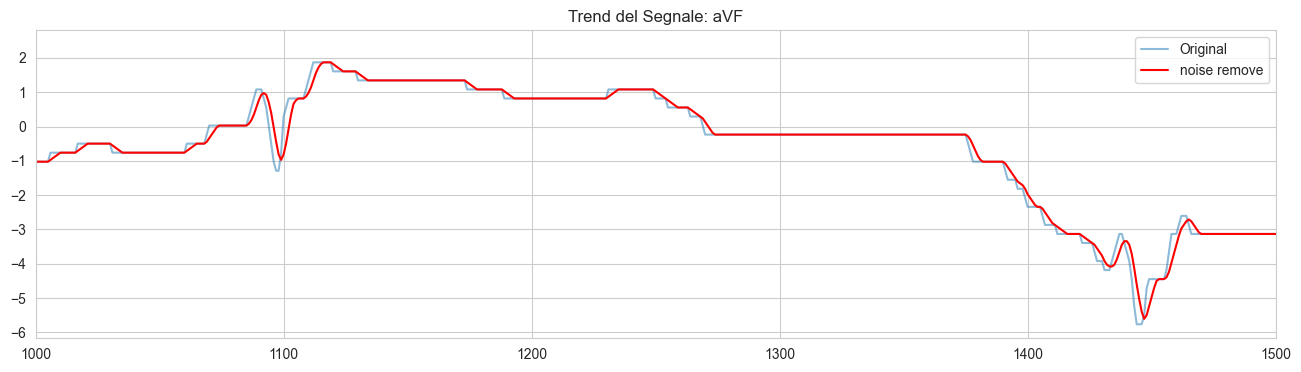

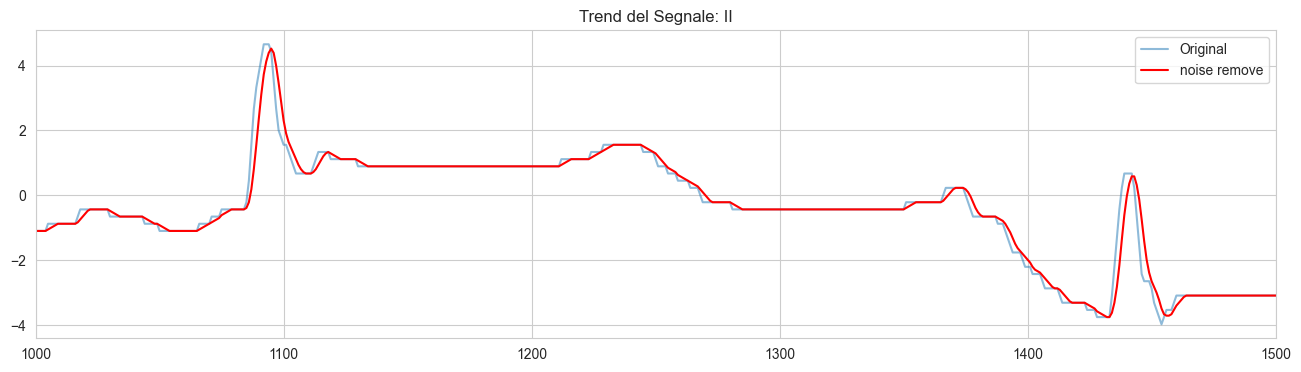

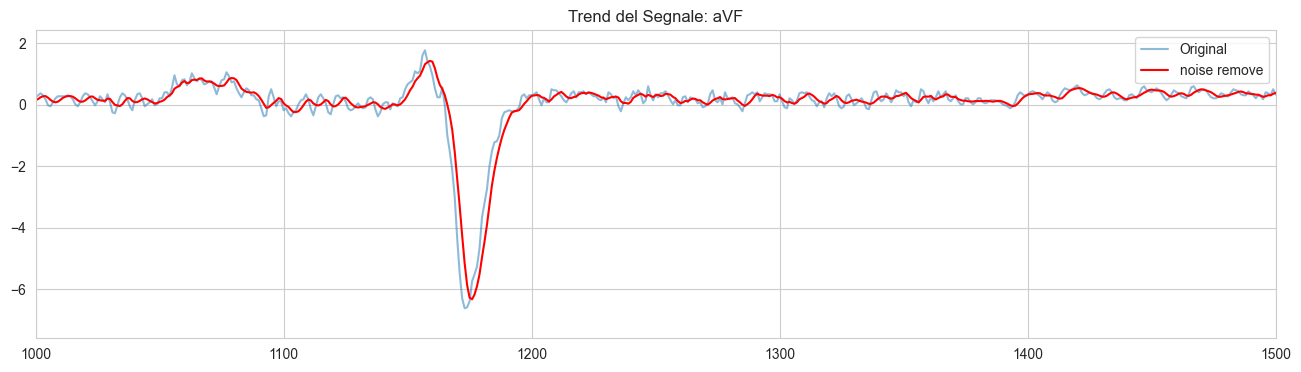

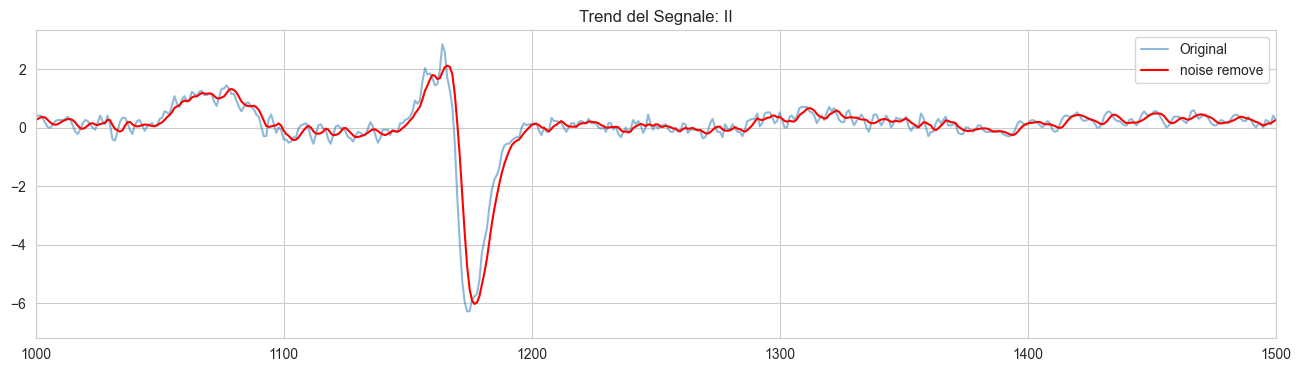

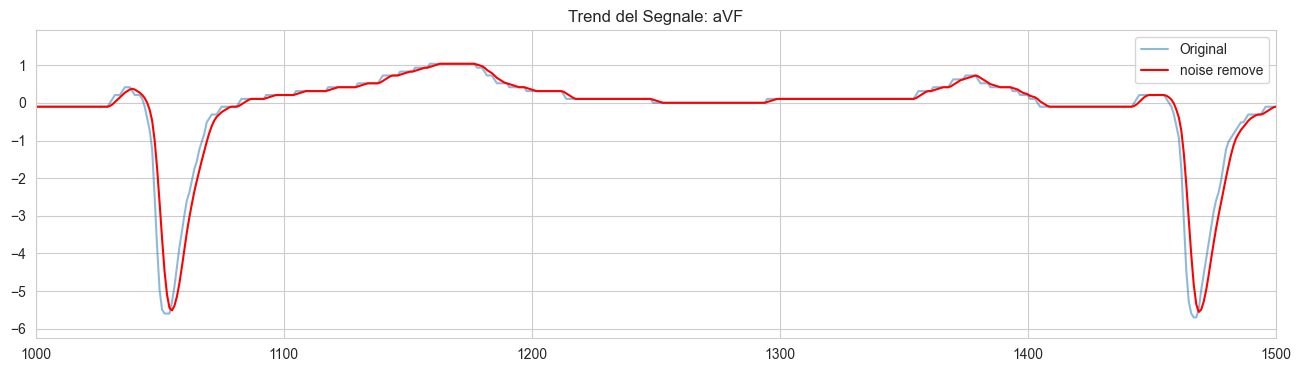

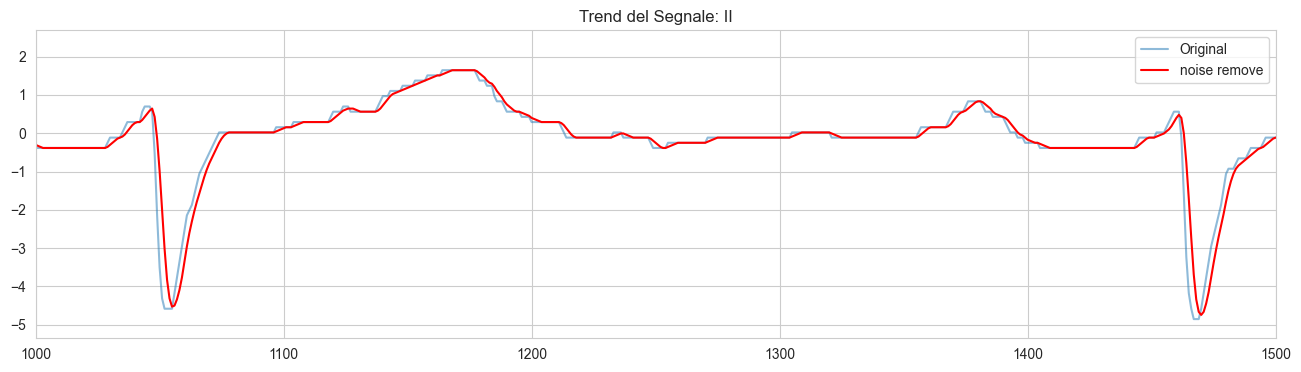

In [24]:
for df in [df_amplitude_scaling_list[20], df_amplitude_scaling_list[10], df_amplitude_scaling_list[100]]:
    for column in ['aVF', 'II']:
        plt.figure(figsize=(16, 4))
        plt.xlim(1000, 1500)  # Mostra solo le righe 1000-1500
        plt.title(f"Trend del Segnale: {column}")
        plt.grid(True)
        plt.plot(df[column], label="Original", alpha=0.5)
        w = 5
        # plt.plot(df[column].rolling(window=10).mean().bfill(), label="noise remove")
        plt.plot(((df[column] - df[column].mean())/df[column].std()).rolling(window=w).mean(), label="noise remove", color="red", linewidth=1.5)
        # plt.plot(df[column] - df[column].rolling(window=w).mean().bfill(), label="Trend shifted")
        plt.legend()
        plt.show()
    # ts_shift = ts - ts.rolling(window=10).mean()

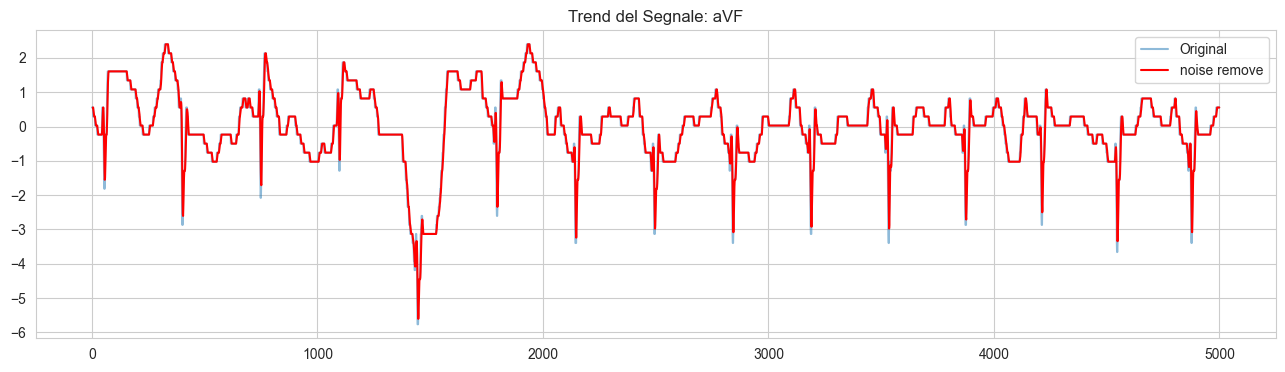

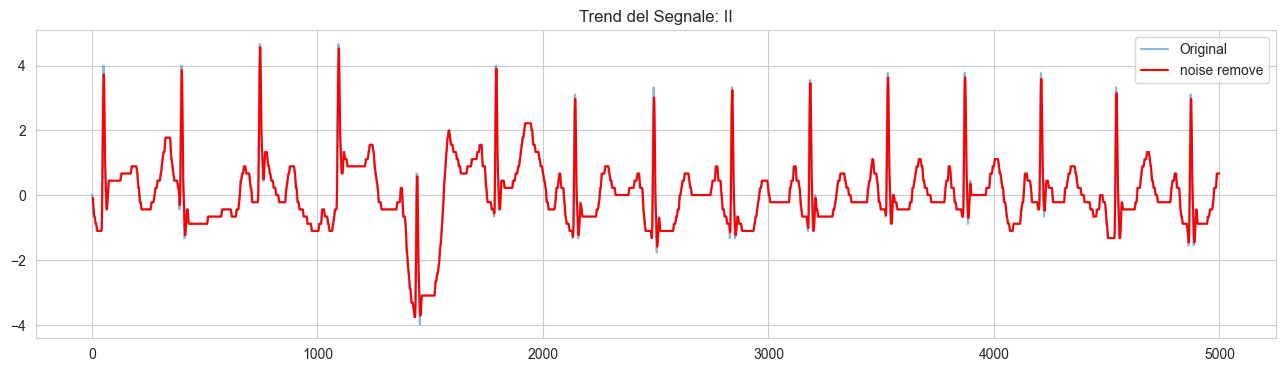

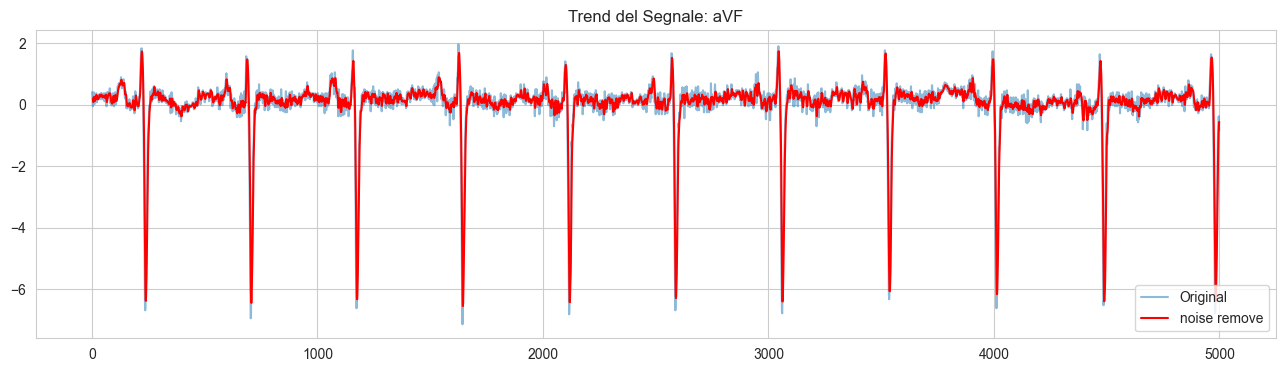

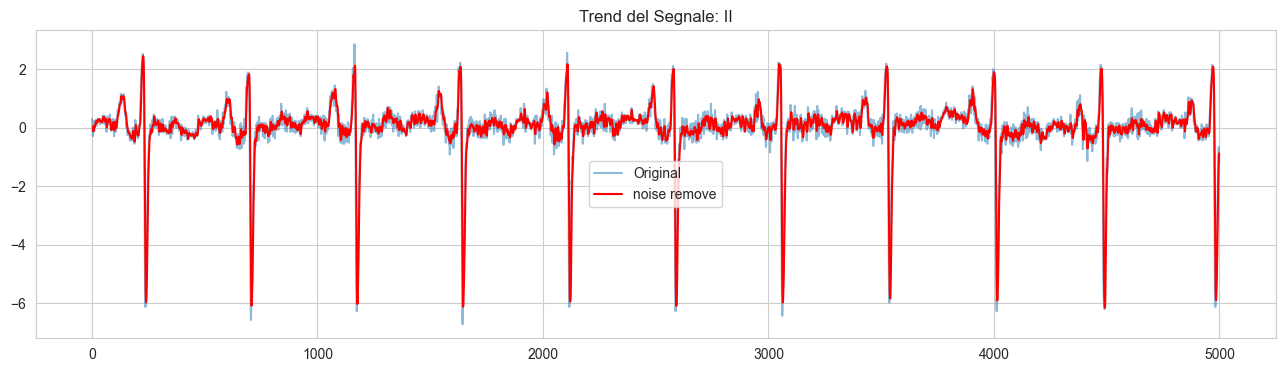

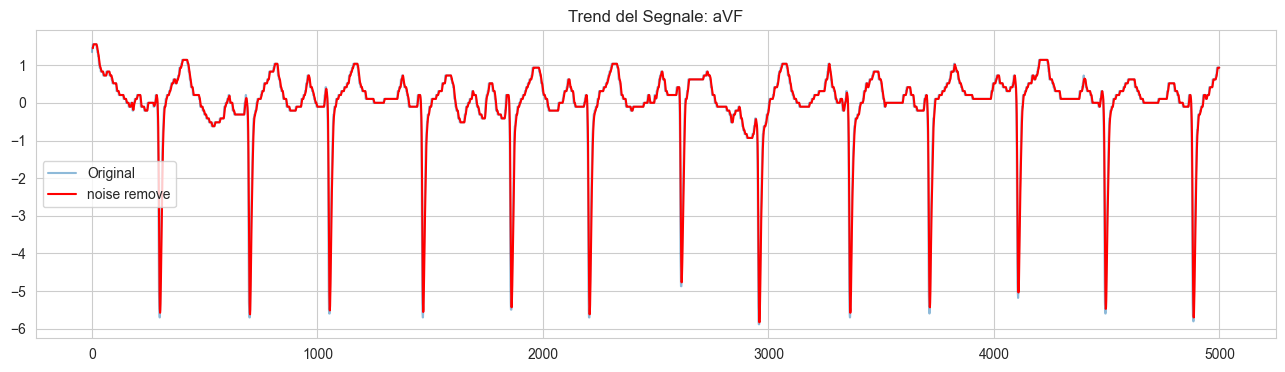

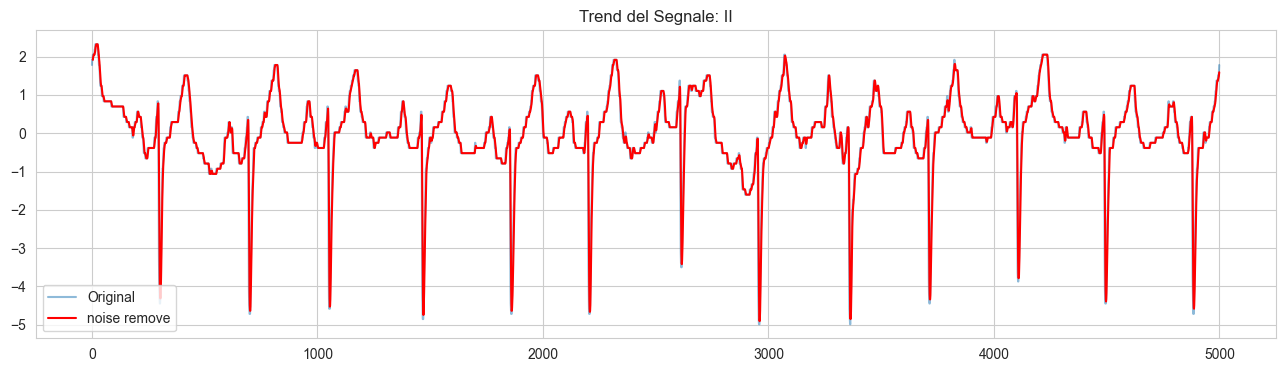

In [25]:
for df in [df_amplitude_scaling_list[20], df_amplitude_scaling_list[10], df_amplitude_scaling_list[100]]:
    for column in ['aVF', 'II']:
        plt.figure(figsize=(16, 4))
        # plt.xlim(1000, 1500)  # Mostra solo le righe 1000-1500
        plt.title(f"Trend del Segnale: {column}")
        plt.grid(True)
        plt.plot(df[column], label="Original", alpha=0.5)
        w = 5
        # plt.plot(df[column].rolling(window=10).mean().bfill(), label="noise remove")
        plt.plot(((df[column] - df[column].mean())/df[column].std()).rolling(window=w).mean(), label="noise remove", color="red", linewidth=1.5)
        # plt.plot(df[column] - df[column].rolling(window=w).mean().bfill(), label="Trend shifted")
        plt.legend()
        plt.show()
    # ts_shift = ts - ts.rolling(window=10).mean()

In [28]:
# Linear Trend fatto su dataset traslato
# Lista per salvare i DataFrame aggiornati con l'offset translation applicato
df_noise_remove_list = []

# Itera comportamento per ciascun ECG di ogni paziente
for df in df_amplitude_scaling_list:
    # Crea una copia del DataFrame per l'offset translation
    df_noise_remove = df.copy()

    for column in df.columns:  # Applica l'offset translation a ciascun segnale
        df_noise_remove[column] = (((df[column] - df[column].mean())/df[column].std()).rolling(window=5).mean())#.interpolate(method='polynomial', order=3)
        df_noise_remove[column] = df_noise_remove[column].bfill()
        df_noise_remove[column] = df_noise_remove[column].ffill()

    df_noise_remove_list.append(df_noise_remove)

In [29]:
# Controllo valori mancanti post rimozione terza distorsione
remove_patient = []
for i, df in enumerate(df_noise_remove_list):
    j = 0
    for column in df.columns:
        nan_in_column = df[column].isnull().sum()
        if nan_in_column > 0:
            j+=1
            print(f"{i} Numero di NaN nella colonna '{column}': {nan_in_column}")
            if j == 1:
                remove_patient.append((i, all_file_list[i]))
print(remove_patient)

[]


---
### Saving Cleaning Data

In [50]:
# df_cleaned_list contiene i DataFrame ripuliti
# e all_file_list contiene i nomi dei file corrispondenti

output_directory = "../datasets/cleaned_times_series"  # Directory di output per salvare i file CSV
os.makedirs(output_directory, exist_ok=True)
df_noise_remove_list
# Salva ogni DataFrame nella lista con il nome corrispondente
for i, (df, file_name) in enumerate(zip(df_noise_remove_list, all_file_list)):
    # Genera il nome del file di output (mantieni l'estensione .csv)
    output_file = os.path.join(output_directory, os.path.basename(file_name).replace('.csv', '_cleaned.csv'))

    # Salva il DataFrame come CSV
    df.to_csv(output_file, index=False)


### **Matrix Correlation**

In [51]:
# Directory contenente i file CSV
output_directory = "../datasets/cleaned_times_series"

# Lista per memorizzare i DataFrame di ciascun file
dataframes = []

# Leggi tutti i file CSV nella directory
for file in os.listdir(output_directory):
    if file.endswith(".csv"):
        file_path = os.path.join(output_directory, file)
        df = pd.read_csv(file_path)  # Carica il file CSV
        dataframes.append(df)       # Aggiungi il DataFrame alla lista

# Combina tutti i DataFrame in uno unico
all_ecg_data = pd.concat(dataframes, ignore_index=True)

print(all_ecg_data.head())


          I        II       III       aVR       aVF      aVL        V1  \
0 -2.409693 -0.210975  1.089073  1.070715  0.433654 -2.04333  0.443598   
1 -2.409693 -0.210975  1.089073  1.070715  0.433654 -2.04333  0.443598   
2 -2.409693 -0.210975  1.089073  1.070715  0.433654 -2.04333  0.443598   
3 -2.409693 -0.210975  1.089073  1.070715  0.433654 -2.04333  0.443598   
4 -2.409693 -0.210975  1.089073  1.070715  0.433654 -2.04333  0.443598   

         V2      V3        V4        V5        V6  
0  0.187277 -0.2323 -0.231272  0.124363 -0.265324  
1  0.187277 -0.2323 -0.231272  0.124363 -0.265324  
2  0.187277 -0.2323 -0.231272  0.124363 -0.265324  
3  0.187277 -0.2323 -0.231272  0.124363 -0.265324  
4  0.187277 -0.2323 -0.231272  0.124363 -0.265324  


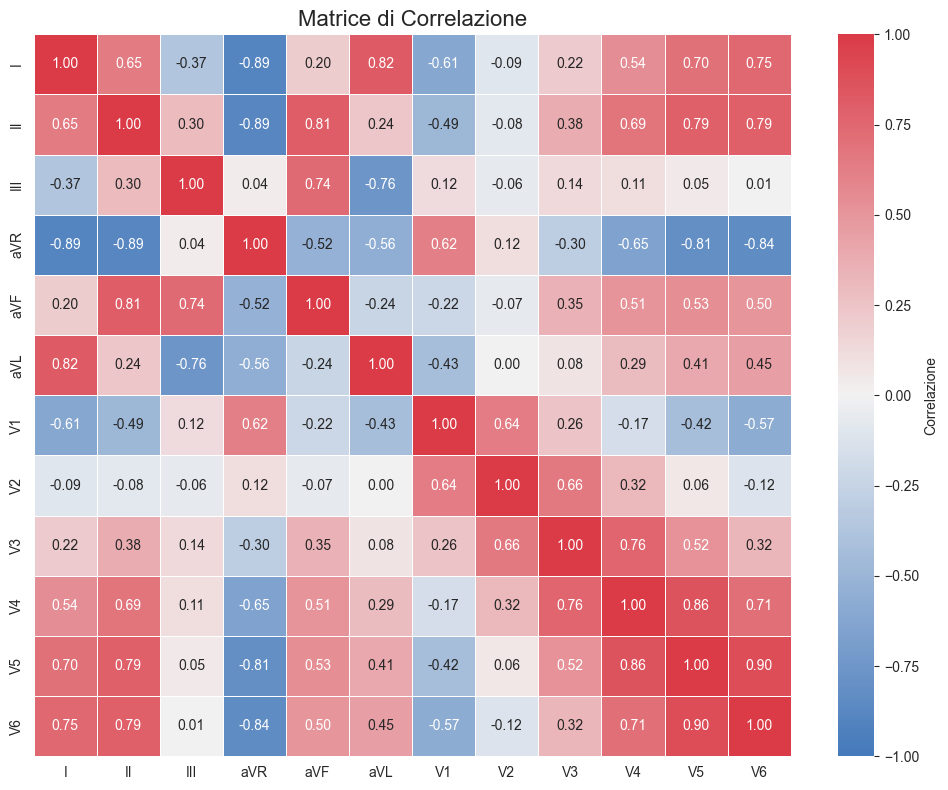

In [61]:
# Calcola la matrice di correlazione
correlation_matrix = all_ecg_data.corr()  # Supponendo che i dati siano combinati

# Plot della matrice di correlazione con colori personalizzati
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,                 # Mostra i valori nella matrice
    fmt=".2f",                  # Mostra i valori con due cifre decimali
    cmap=sns.diverging_palette(250, 10, as_cmap=True),  # Palette che enfatizza negativi e positivi
    vmin=-1, vmax=1,
    center=0,
    linewidths=0.5,
    cbar_kws={'label': 'Correlazione'}
)
plt.title("Matrice di Correlazione", fontsize=16)
plt.tight_layout()
plt.show()


### **PCA**

In [67]:
all_ecg_data

,I,II,III,aVR,aVF,aVL,V1,V2,V3,V4,V5,V6
0,-2.416515,-0.221080,1.081577,1.082513,0.423558,-2.044924,0.442934,0.197579,-0.225087,-0.233420,0.124363,-0.258138
1,-2.416515,-0.221080,1.081577,1.082513,0.423558,-2.044924,0.442934,0.197579,-0.225087,-0.233420,0.124363,-0.258138
2,-2.416515,-0.221080,1.081577,1.082513,0.423558,-2.044924,0.442934,0.197579,-0.225087,-0.233420,0.124363,-0.258138
3,-2.416515,-0.221080,1.081577,1.082513,0.423558,-2.044924,0.442934,0.197579,-0.225087,-0.233420,0.124363,-0.258138
4,-2.416515,-0.221080,1.081577,1.082513,0.423558,-2.044924,0.442934,0.197579,-0.225087,-0.233420,0.124363,-0.258138
...,...,...,...,...,...,...,...,...,...,...,...,...
5494995,0.372381,0.273420,-0.067213,-0.384946,0.113732,0.242892,-0.301532,0.179054,0.359245,0.396529,0.362966,0.266605
5494996,0.347079,0.280093,-0.038493,-0.372483,0.132011,0.211459,-0.285950,0.190772,0.368063,0.411348,0.362966,0.266605
5494997,0.339850,0.286767,-0.025728,-0.372483,0.142978,0.199672,-0.274264,0.206397,0.376882,0.421228,0.362966,0.266605
5494998,0.329006,0.280093,-0.022537,-0.360020,0.139322,0.191814,-0.270369,0.222022,0.390110,0.426168,0.366714,0.270702


In [53]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

columns = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
# df = pd.concat(df_cleaned_list, ignore_index=True)  # Combina i dati di tutti i pazienti

# Standardizza i dati
scaler = StandardScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(all_ecg_data), columns=all_ecg_data.columns)

# Applica la PCA direttamente sui dati normalizzati
pca = PCA()
pca.fit(df_scaled)


PCA()

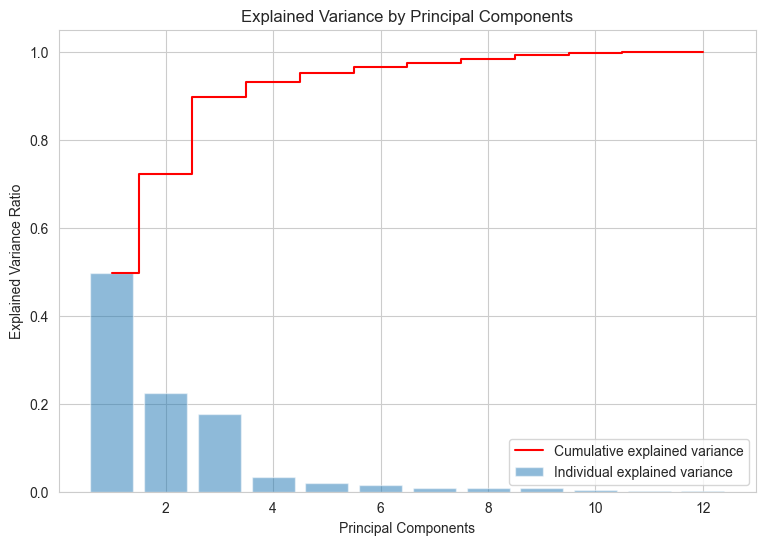

Most Important Leads for the First 3 Principal Components:
PC1: aVR, V5, V6
PC2: III, aVL, aVF
PC3: V2, V3, III
PC4: V5, V4, II
PC5: V3, V1, V6
PC6: V2, V1, aVL


In [57]:
# Extract the explained variance ratios
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Plot the explained variance ratios to visualize how much variance each component explains
plt.figure(figsize=(9, 6))
plt.bar(range(1, len(explained_variance) + 1), explained_variance, alpha=0.5, align='center',
        label='Individual explained variance')
plt.step(range(1, len(cumulative_variance) + 1), cumulative_variance, where='mid',
         label='Cumulative explained variance', color='red')
plt.xlabel('Principal Components')
plt.ylabel('Explained Variance Ratio')
plt.title('Explained Variance by Principal Components')
plt.legend(loc='best')
plt.grid(True)
plt.show()

# Analyze PCA components
components_df = pd.DataFrame(pca.components_, columns=df_scaled.columns)

# Identify the most important leads based on the absolute values of the loadings
most_important_leads = {}
num_components = 6  # Specify how many components to analyze PC1, PC", ...
for i in range(num_components):
    component = components_df.iloc[i]
    # Top 2 leads per component by setting head(2) and 3 putting head(3)
    top_leads = component.abs().sort_values(ascending=False).head(3).index.tolist()
    most_important_leads[f"PC{i + 1}"] = top_leads

print("Most Important Leads for the First 3 Principal Components:")
for pc, leads in most_important_leads.items():
    print(f"{pc}: {', '.join(leads)}")



In [ ]:
# https://ecgwaves.com/topic/ekg-ecg-leads-electrodes-systems-limb-chest-precordial/